# Phase 1: Supervised Learning - Evaluation, Comparison and Conclusion
**SWE485 - Team Project | SW485-Project-Group2**

This notebook has these sections of `Phase1_Supervised_Learning.ipynb`:

| Section | Content |
|---------|---------|
| 4.3 | Side-by-side metrics and ROC curves for both models |
| 5 | Model Comparison & Analysis |
| 6 | Conclusion: Best Model Selection & Reasoning |
| 7 | Next Steps for Phase 2 Integration |

I use the same data, the same train/test split, `random_state=42` and the same stratified 5-fold CV as the shared Setup cell. The classes are imbalanced (about 25% positive), so I do not judge the models by accuracy alone.

## Setup
This is the same code as the shared Setup cell, so the numbers match the team notebook.

In [1]:
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

# Model 1 was saved with an older scikit-learn, so hide the version warnings
warnings.filterwarnings("ignore", module="sklearn")

RANDOM_STATE = 42

# folders from the project structure
RESULTS_DIR = "Supervised_Learning/evaluation_results"
PLOTS_DIR = "Supervised_Learning/plots"

# same data and split as the shared Setup cell
df = pd.read_csv("Dataset/preprocessed_data.csv")
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# same 5-fold stratified CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate (train):", round(y_train.mean(), 4), "| (test):", round(y_test.mean(), 4))

Train: (14916, 32) | Test: (3729, 32)
Positive rate (train): 0.2464 | (test): 0.2464


In [2]:
# shared helper from the team notebook
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }

### Load Model 1 and rebuild Model 2
Model 1 (Logistic Regression) is loaded from the saved file. Model 2 (XGBoost) was not saved, so I train it again with the best parameters from Section 3.2.

In [3]:
# Model 1: tuned Logistic Regression (saved file)
logreg_model = joblib.load("Supervised_Learning/models/model1_logistic_regression.joblib")

# Model 2: XGBoost with the best parameters from Section 3.2
xgb_model = xgb.XGBClassifier(
    learning_rate=0.1,
    max_depth=5,
    n_estimators=50,
    subsample=1.0,
    random_state=RANDOM_STATE,
    eval_metric="logloss",
)
xgb_model.fit(X_train, y_train)

LR_NAME = "Logistic Regression"
XGB_NAME = "XGBoost"
models = {LR_NAME: logreg_model, XGB_NAME: xgb_model}

# test predictions and probabilities
preds = {name: m.predict(X_test) for name, m in models.items()}
probs = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

# check the loaded Model 1 against its saved predictions
saved = pd.read_csv(f"{RESULTS_DIR}/model1_logreg_test_predictions.csv", index_col=0)
print("Model 1 predictions match the saved file:", (saved["y_pred"].values == preds[LR_NAME]).all())

Model 1 predictions match the saved file: True


**Check.** The loaded Model 1 gives the same test predictions as its saved file. The rebuilt Model 2 gives the same test numbers as the tuned model in Section 3.2 (F1 0.5816, ROC-AUC 0.8159, see the table below). So these are the same two models the team trained.

## 4.3 Side-by-Side Metrics and ROC Curves

### Test-set metrics

In [4]:
# test metrics and confusion matrix counts for both models (threshold 0.5)
rows = []
for name, m in models.items():
    row = evaluate_model(name, m, X_test, y_test)
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    row.update({"TN": tn, "FP": fp, "FN": fn, "TP": tp})
    rows.append(row)
metrics_table = pd.DataFrame(rows).set_index("Model")
metrics_table.to_csv(f"{RESULTS_DIR}/metrics_comparison.csv")

metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
display(metrics_table[metric_cols].round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.7316,0.4723,0.7595,0.5824,0.7865
XGBoost,0.7986,0.5959,0.5680,0.5816,0.8159


**Interpretation.** The two models have almost the same F1 (0.582 and 0.582), but for different reasons. Logistic Regression has high recall (0.76) and low precision (0.47). It finds most of the candidates who are looking for a job, but it also gives many false alarms. XGBoost has higher precision (0.60) and accuracy (0.80) but lower recall (0.57). It is right more often when it flags someone, but it misses more leavers. XGBoost also has the higher ROC-AUC (0.816 vs 0.786), so it is better at ranking candidates by risk. Accuracy alone is not enough here, because a model that always says "not looking" already gets about 75%.

### 5-fold cross-validation (mean and std)

In [5]:
# 5-fold CV on the training set for both models
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = []
for name, m in models.items():
    scores = cross_validate(clone(m), X_train, y_train, cv=cv, scoring=scoring)
    for s in scoring:
        cv_rows.append({"Model": name, "Metric": s,
                        "mean": scores[f"test_{s}"].mean(),
                        "std": scores[f"test_{s}"].std()})

cv_long = pd.DataFrame(cv_rows)
cv_long.to_csv(f"{RESULTS_DIR}/cv_results.csv", index=False)

# show it as mean +/- std
cv_long["mean +/- std"] = cv_long["mean"].map("{:.4f}".format) + " +/- " + cv_long["std"].map("{:.4f}".format)
cv_table = cv_long.pivot(index="Metric", columns="Model", values="mean +/- std").loc[scoring]
display(cv_table)

Model,Logistic Regression,XGBoost
Metric,,
accuracy,0.7308 +/- 0.0115,0.7978 +/- 0.0084
precision,0.4706 +/- 0.0149,0.5935 +/- 0.0184
recall,0.7375 +/- 0.0290,0.5710 +/- 0.0226
f1,0.5745 +/- 0.0185,0.5818 +/- 0.0182
roc_auc,0.7780 +/- 0.0168,0.8003 +/- 0.0165


**Interpretation.** The CV means are close to the test numbers, and the standard deviations are small (about 0.01 to 0.03). So both models are stable, and the test result is not just a lucky split. The pattern is the same as on the test set. Logistic Regression has higher recall (0.74 vs 0.57). XGBoost has higher precision (0.59 vs 0.47) and accuracy. F1 is almost equal (0.575 vs 0.582). XGBoost has the higher mean ROC-AUC (0.800 vs 0.778). The difference is not big, but it is in the same direction as on the test set.

### Confusion matrix heatmaps

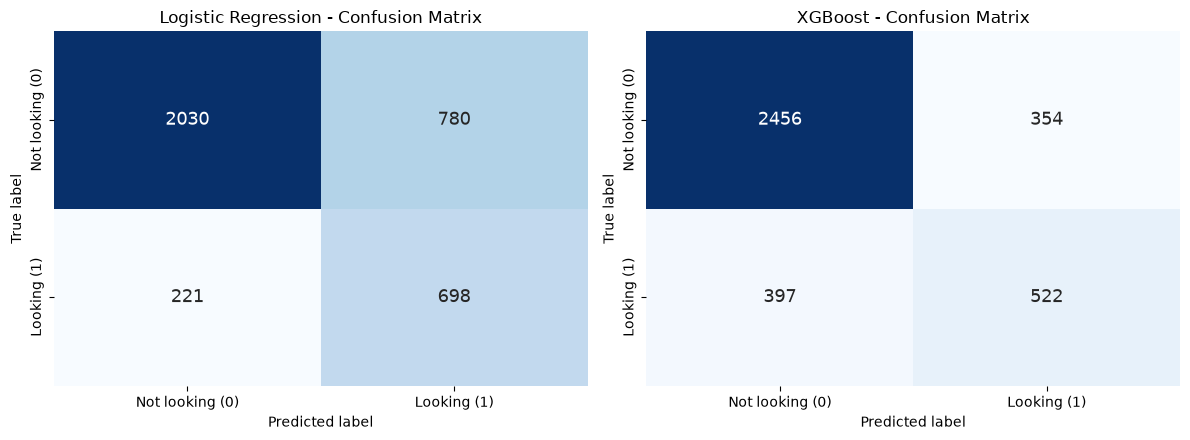

In [6]:
# confusion matrices side by side
labels = ["Not looking (0)", "Looking (1)"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels, annot_kws={"size": 13})
    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/confusion_matrices.png", dpi=150)
plt.show()

**Interpretation.** The test set has 919 candidates who are really looking for a job. Logistic Regression misses 221 of them and XGBoost misses 397. On the other side, Logistic Regression wrongly flags 780 candidates who are not looking, and XGBoost wrongly flags only 354. So at the 0.5 threshold, Logistic Regression catches more leavers but gives more false alarms, and XGBoost gives fewer false alarms but misses more leavers. For HR, a missed leaver usually costs more than a false alarm. So the 397 misses are the main weakness of XGBoost at this threshold.

### ROC curves on one plot

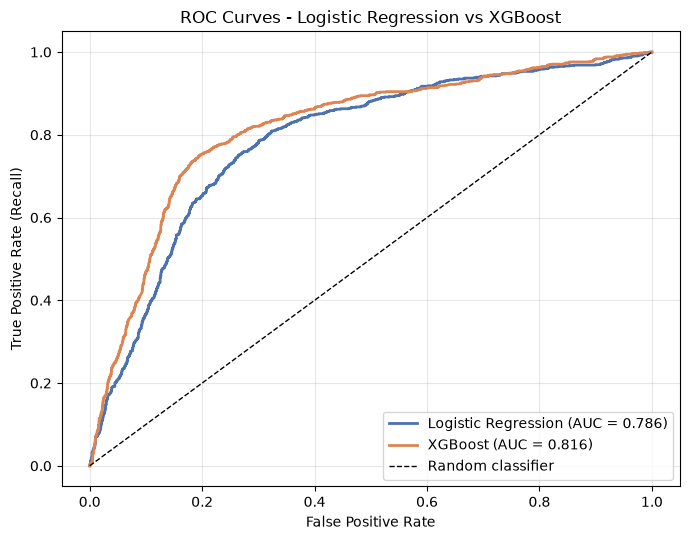

In [7]:
# both ROC curves on the same plot
colors = {LR_NAME: "#4C72B0", XGB_NAME: "#DD8452"}
plt.figure(figsize=(7, 5.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    auc = roc_auc_score(y_test, probs[name])
    plt.plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves - Logistic Regression vs XGBoost")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/roc_curves.png", dpi=150)
plt.show()

**Interpretation.** Both curves are far above the random line, so both models are much better than guessing. The XGBoost curve is above the Logistic Regression curve on the left side of the plot, up to a false positive rate of about 0.5. After that the two curves are almost the same (AUC 0.816 vs 0.786). The left side is the part we care about, because the system should not give too many false alarms. There, XGBoost catches more leavers for the same rate of false alarms. This also shows that the low recall of XGBoost in the table comes from the 0.5 threshold. It does not mean the model is worse at finding leavers.

## 5. Model Comparison & Analysis

### 5.1 Which model performed best, and why?

At the 0.5 threshold the two models have the same F1, so the answer depends on the metric:

- **Ranking (ROC-AUC):** XGBoost is better on the test set (0.816 vs 0.786) and in cross-validation (0.800 vs 0.778). This metric does not depend on the threshold.
- **Recall at 0.5:** Logistic Regression is better (0.76 vs 0.57).

The recall difference comes mostly from how the models were trained. Logistic Regression used `class_weight="balanced"`, so it predicts the minority class more often. XGBoost was trained without class weights, so at 0.5 it flags fewer candidates. To compare them fairly, I choose a threshold for each model using only the training data (out-of-fold predictions from the same 5-fold CV). Then I apply it one time to the test set.

In [8]:
# pick the threshold with the best F1 on the training folds (test set not used)
thresholds = np.arange(0.10, 0.91, 0.01)
best_thresholds = {}
for name, m in models.items():
    oof_prob = cross_val_predict(clone(m), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    f1_values = [f1_score(y_train, oof_prob >= t) for t in thresholds]
    best_thresholds[name] = round(float(thresholds[int(np.argmax(f1_values))]), 2)
print("Threshold with the best CV F1:", best_thresholds)

# test metrics at a given threshold
def metrics_at(name, t):
    pred = (probs[name] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Model": name, "Threshold": t,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "Missed leavers (FN)": fn, "False alarms (FP)": fp}

thr_rows = []
for name in models:
    thr_rows.append(metrics_at(name, 0.5))
    thr_rows.append(metrics_at(name, best_thresholds[name]))
threshold_table = pd.DataFrame(thr_rows).set_index(["Model", "Threshold"])
display(threshold_table.round(4))

Threshold with the best CV F1: {'Logistic Regression': 0.55, 'XGBoost': 0.32}


Accuracy  Precision  Recall      F1  \
Model               Threshold                                        
Logistic Regression 0.50         0.7316     0.4723  0.7595  0.5824   
                    0.55         0.7490     0.4935  0.7073  0.5814   
XGBoost             0.50         0.7986     0.5959  0.5680  0.5816   
                    0.32         0.7999     0.5755  0.7171  0.6386   

                               Missed leavers (FN)  False alarms (FP)  
Model               Threshold                                          
Logistic Regression 0.50                       221                780  
                    0.55                       269                667  
XGBoost             0.50                       397                354  
                    0.32                       260                486

**Interpretation.** For Logistic Regression the best CV threshold is 0.55. This is close to 0.5 and changes very little (F1 stays at 0.58). For XGBoost the best CV threshold is 0.32, and it changes a lot. Recall goes from 0.57 to 0.72 and F1 goes from 0.58 to 0.64, while accuracy stays at 0.80. Compared with Logistic Regression at 0.5, XGBoost at 0.32 catches a few less leavers (659 vs 698 out of 919) but gives far fewer false alarms (486 vs 780).

So **XGBoost performed best**, but only when its threshold is lowered. The reason is that it ranks candidates better (higher ROC-AUC). It is a tree model, so it can learn non-linear effects and combinations of features. A linear model cannot do that. Logistic Regression looked equal at 0.5 only because class weighting had already moved it to a high-recall point.

### 5.2 Misclassification patterns and challenging categories

In [9]:
# compare the mistakes of the two models on the test set
y_true = y_test.values
lr_wrong = preds[LR_NAME] != y_true
xgb_wrong = preds[XGB_NAME] != y_true

cases = {
    "Both models wrong": lr_wrong & xgb_wrong,
    "Only Logistic Regression wrong": lr_wrong & ~xgb_wrong,
    "Only XGBoost wrong": ~lr_wrong & xgb_wrong,
}
overlap = pd.DataFrame({
    "All errors": [mask.sum() for mask in cases.values()],
    "Missed leavers (FN)": [(mask & (y_true == 1)).sum() for mask in cases.values()],
    "False alarms (FP)": [(mask & (y_true == 0)).sum() for mask in cases.values()],
}, index=list(cases.keys()))
display(overlap)

,All errors,Missed leavers (FN),False alarms (FP)
Both models wrong,548,206,342
Only Logistic Regression wrong,453,15,438
Only XGBoost wrong,203,191,12


**Interpretation.** Both models are wrong on the same 548 test candidates. So a big part of the errors are hard cases, not a problem of one algorithm. 206 leavers are missed by both models. The errors that only one model makes follow the trade-off from Section 4.3. The errors of only Logistic Regression are almost all false alarms (438 of 453). The errors of only XGBoost are almost all missed leavers (191 of 203). Almost every leaver that Logistic Regression misses is also missed by XGBoost (206 of 221).

In [10]:
# error rates in each group of candidates (threshold 0.5)
# numeric features are standardized, so 0 is the average
groups = {
    "Company info": np.where(X_test["company_info_missing"] == 1, "missing", "known"),
    "City development": np.where(X_test["city_development_index"] >= 0, "above average", "below average"),
    "Experience": np.where(X_test["experience"] >= 0, "above average", "below average"),
    "Relevant experience": np.where(X_test["relevent_experience"] == 1, "yes", "no"),
}

group_rows = []
for feature, values in groups.items():
    for value in sorted(set(values)):
        mask = values == value
        pos = mask & (y_true == 1)
        neg = mask & (y_true == 0)
        group_rows.append({
            "Feature": feature, "Group": value, "Candidates": mask.sum(),
            "Looking rate": y_true[mask].mean(),
            "LR miss rate": (preds[LR_NAME][pos] == 0).mean(),
            "XGB miss rate": (preds[XGB_NAME][pos] == 0).mean(),
            "LR false alarm rate": (preds[LR_NAME][neg] == 1).mean(),
            "XGB false alarm rate": (preds[XGB_NAME][neg] == 1).mean(),
        })
group_table = pd.DataFrame(group_rows).set_index(["Feature", "Group"])
display(group_table.round(3))

Candidates  Looking rate  LR miss rate  \
Feature             Group                                                   
Company info        known                2667         0.178         0.378   
                    missing              1062         0.419         0.094   
City development    above average        2462         0.156         0.491   
                    below average        1267         0.421         0.060   
Experience          above average        1551         0.171         0.404   
                    below average        2178         0.300         0.174   
Relevant experience no                   1073         0.332         0.177   
                    yes                  2656         0.212         0.281   

                                   XGB miss rate  LR false alarm rate  \
Feature             Group                                               
Company info        known                  0.481                0.155   
                    missing                0.380                0.713   
City development    above average          0.649                0.119   
                    below average          0.275                0.726   
Experience          above average          0.634                0.172   
                    below average          0.350                0.367   
Relevant experience no                     0.421                0.434   
                    yes                    0.439                0.224   

                                   XGB false alarm rate  
Feature             Group                                
Company info        known                         0.079  
                    missing                       0.292  
City development    above average                 0.039  
                    below average                 0.372  
Experience          above average                 0.052  
                    below average                 0.188  
Relevant experience no                            0.185  
                    yes                           0.106

**Interpretation.** The miss rate is the share of real leavers in a group that the model did not flag. The false alarm rate is the share of candidates who are not looking but were flagged.

The hardest candidates for both models are the leavers who look "safe". In cities with above-average development, Logistic Regression misses 49% of the real leavers and XGBoost misses 65%. For candidates with above-average experience, the miss rates are 40% and 63%. Only about 16% to 17% of these groups are looking for a job, so both models learn to say "not looking" for them.

The high-risk groups have the opposite problem. These are candidates with below-average city development or missing company information, where about 42% are looking. Here Logistic Regression flags almost everyone, so its false alarm rate is very high (73% and 71%). XGBoost is more careful in these groups (37% and 29% false alarms), but it misses more of the leavers (28% and 38%).

At the 0.5 threshold XGBoost misses a larger share of leavers than Logistic Regression in every group. The biggest gap is for candidates with missing company information (9% vs 38%). These are high-risk candidates that XGBoost scores a little under 0.5. This is one more reason to lower its threshold.

### 5.3 Trade-offs: accuracy vs interpretability vs computational cost

| | Logistic Regression | XGBoost |
|---|---|---|
| **Predictive performance** | ROC-AUC 0.786, F1 0.58. Good recall at 0.5 because of class weighting. | ROC-AUC 0.816. F1 is 0.58 at 0.5 and 0.64 at the tuned threshold. Better ranking. |
| **Interpretability** | High. Each feature has one coefficient. It is easy to turn it into an odds ratio ("3 times the odds") and explain it to HR leaders. | Lower. We cannot read 50 trees directly. Feature importance shows what matters but not the direction, so extra tools such as SHAP are needed. |
| **Computational cost** | Low. Small grid search (50 fits). | Low to train one time, but it has more parameters to tune (270 fits), and the threshold also needs tuning. |

Computational cost is not a problem for this dataset (about 15,000 training rows and 32 features). Both models train in about a second. The real difference is in tuning: XGBoost needed 270 grid search fits and Logistic Regression needed 50.

The main trade-off is between a bit more predictive power (XGBoost) and a much simpler explanation (Logistic Regression). The gain from XGBoost is real but not large: about 0.02 to 0.03 in ROC-AUC, and 0.06 in F1 after threshold tuning. `company_info_missing` and `city_development_index` are among the strongest drivers in both models. So the explanation we give to leadership does not conflict with the model that makes the predictions.

## 6. Conclusion: Best Model Selection & Reasoning

**Selected model for the final system: XGBoost (Model 2, with the tuned parameters), used with a decision threshold of 0.32 instead of 0.5.**

Reasons:

1. **It ranks candidates better.** XGBoost has the higher ROC-AUC on the test set (0.816 vs 0.786) and in cross-validation (mean 0.800 vs 0.778). The system should rank candidates by job-change risk, so this is the most important metric. It also does not depend on the threshold.
2. **It has a better balance after the threshold is fixed.** With the threshold chosen on the training folds (0.32), XGBoost gets recall 0.72, precision 0.58 and F1 0.64 on the test set. Logistic Regression gets recall 0.76, precision 0.47 and F1 0.58. XGBoost finds almost as many leavers with about 300 fewer false alarms. So HR spends less time on candidates who were not going to leave.
3. **It is stable.** The CV standard deviations are small and the test numbers agree with the CV means, so there is no sign of overfitting.
4. **Cost is not a problem** at this data size.

Conditions and limits of this choice:

- **The threshold matters.** At 0.5, XGBoost misses 397 of 919 leavers (recall 0.57). This is too many for a retention tool. If the model is used at 0.5, Logistic Regression is the safer choice. HR can also lower the threshold more if they want to catch more leavers and accept more false alarms.
- **Logistic Regression stays as the explanation model.** Its coefficients and odds ratios give a clear story about the key drivers for leadership. It is also a good baseline to check the XGBoost predictions.
- **The performance is moderate.** Precision is around 0.58, so about 4 of every 10 flagged candidates are not really looking. The output should be used as a risk score to help HR decide who to talk to first. It should not be an automatic decision about a person. About 200 leavers are missed by both models. They are mostly experienced candidates in developed cities, and the features we have cannot separate them well.

## 7. Next Steps for Phase 2 Integration

**Before Phase 2 starts**
- Save the final XGBoost model with `joblib` in `Supervised_Learning/models/` together with the chosen threshold. It was not saved in Phase 1, and this way Phase 2 does not need to train it again.
- Score all candidates. Store the predicted probability (risk score) and a risk level (for example low / medium / high) next to each row.

**Clustering (unsupervised learning)**
- Cluster the candidates on the same preprocessed features (for example K-Means, choosing the number of clusters with the elbow method and the silhouette score). Save the result as `Dataset/clustered_data.csv`.
- Combine the two outputs. For each cluster, report its size, its average risk score and its share of high-risk candidates. This gives segments such as "early-career candidates in low-development cities with no company information". Segments are easier for HR to act on than single predictions.
- Look at the clusters where the model makes most of its errors (Section 5.2), especially experienced candidates in developed cities. They may be a separate segment that needs a different approach.

**Generative AI executive briefings**
- Build structured prompt templates that receive facts from our code: the model metrics, the top drivers (Logistic Regression odds ratios and XGBoost importances) and the risk summary of each cluster.
- The language model only writes the text of the briefing (summary, key risks, recommended retention actions). All numbers come from our tables, and the prompt tells the model not to add numbers that were not given.
- Send only aggregated numbers to the language model, not single candidate records. Keep the API key out of the repository (`.env` is already in `.gitignore`).
- Include the model limits in the briefing (precision around 0.58), so executives read the score as a signal and not as a sure fact.

**Executive dashboard**
- Overview: number of candidates, share at high risk and the main model metrics.
- Risk view: the distribution of risk scores, with filters for city development, experience and company information.
- Threshold control: a slider that shows how recall, precision and the number of flagged candidates change. It starts at 0.32.
- Drivers view: the key drivers chart from Logistic Regression.
- Segments view: the clusters with their risk level and the generated briefing for each one.